# California Housing: Predicting Median House Value
**OLS vs Ridge (L2) vs Lasso (L1) regression**

Pipeline:
1. Load data
2. Impute missing values and inspect correlations
3. Engineer interaction features
4. Diagnose and handle multicollinearity (VIF)
5. Standardize numeric features and one-hot encode `ocean_proximity`
6. Fit OLS, and Ridge / Lasso tuned with `GridSearchCV`
7. Compare on RMSE, MAE and R²
8. Plot predicted vs actual and residual distributions

## 1. Imports and data loading

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
RANDOM_STATE = 42

In [2]:
df = pd.read_csv("housing.csv")
print("Shape:", df.shape)
df.head()

Shape: (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
longitude,20640.0,-119.569704,2.003532,-124.3500,-121.8000,-118.4900,-118.01000,-114.3100
latitude,20640.0,35.631861,2.135952,32.5400,33.9300,34.2600,37.71000,41.9500
housing_median_age,20640.0,28.639486,12.585558,1.0000,18.0000,29.0000,37.00000,52.0000
total_rooms,20640.0,2635.763081,2181.615252,2.0000,1447.7500,2127.0000,3148.00000,39320.0000
total_bedrooms,20433.0,537.870553,421.385070,1.0000,296.0000,435.0000,647.00000,6445.0000
population,20640.0,1425.476744,1132.462122,3.0000,787.0000,1166.0000,1725.00000,35682.0000
households,20640.0,499.539680,382.329753,1.0000,280.0000,409.0000,605.00000,6082.0000
median_income,20640.0,3.870671,1.899822,0.4999,2.5634,3.5348,4.74325,15.0001
median_house_value,20640.0,206855.816909,115395.615874,14999.0000,119600.0000,179700.0000,264725.00000,500001.0000


## 2. Missing values

In [5]:
missing = df.isna().sum().to_frame("missing")
missing["pct"] = (missing["missing"] / len(df) * 100).round(2)
missing[missing["missing"] > 0]

,missing,pct
total_bedrooms,207,1.0


Only `total_bedrooms` has missing values. We use **median imputation** (robust to the heavy right skew in this column).

For the exploratory heatmap below we impute on the whole dataset (EDA only). For the actual models, the imputer lives **inside the pipeline** and is fitted on the training folds only, so there is no data leakage.

In [6]:
eda = df.copy()
eda["total_bedrooms"] = eda["total_bedrooms"].fillna(eda["total_bedrooms"].median())
print("Missing after imputation:", eda.isna().sum().sum())

Missing after imputation: 0


## 3. Exploratory analysis and correlation heatmap

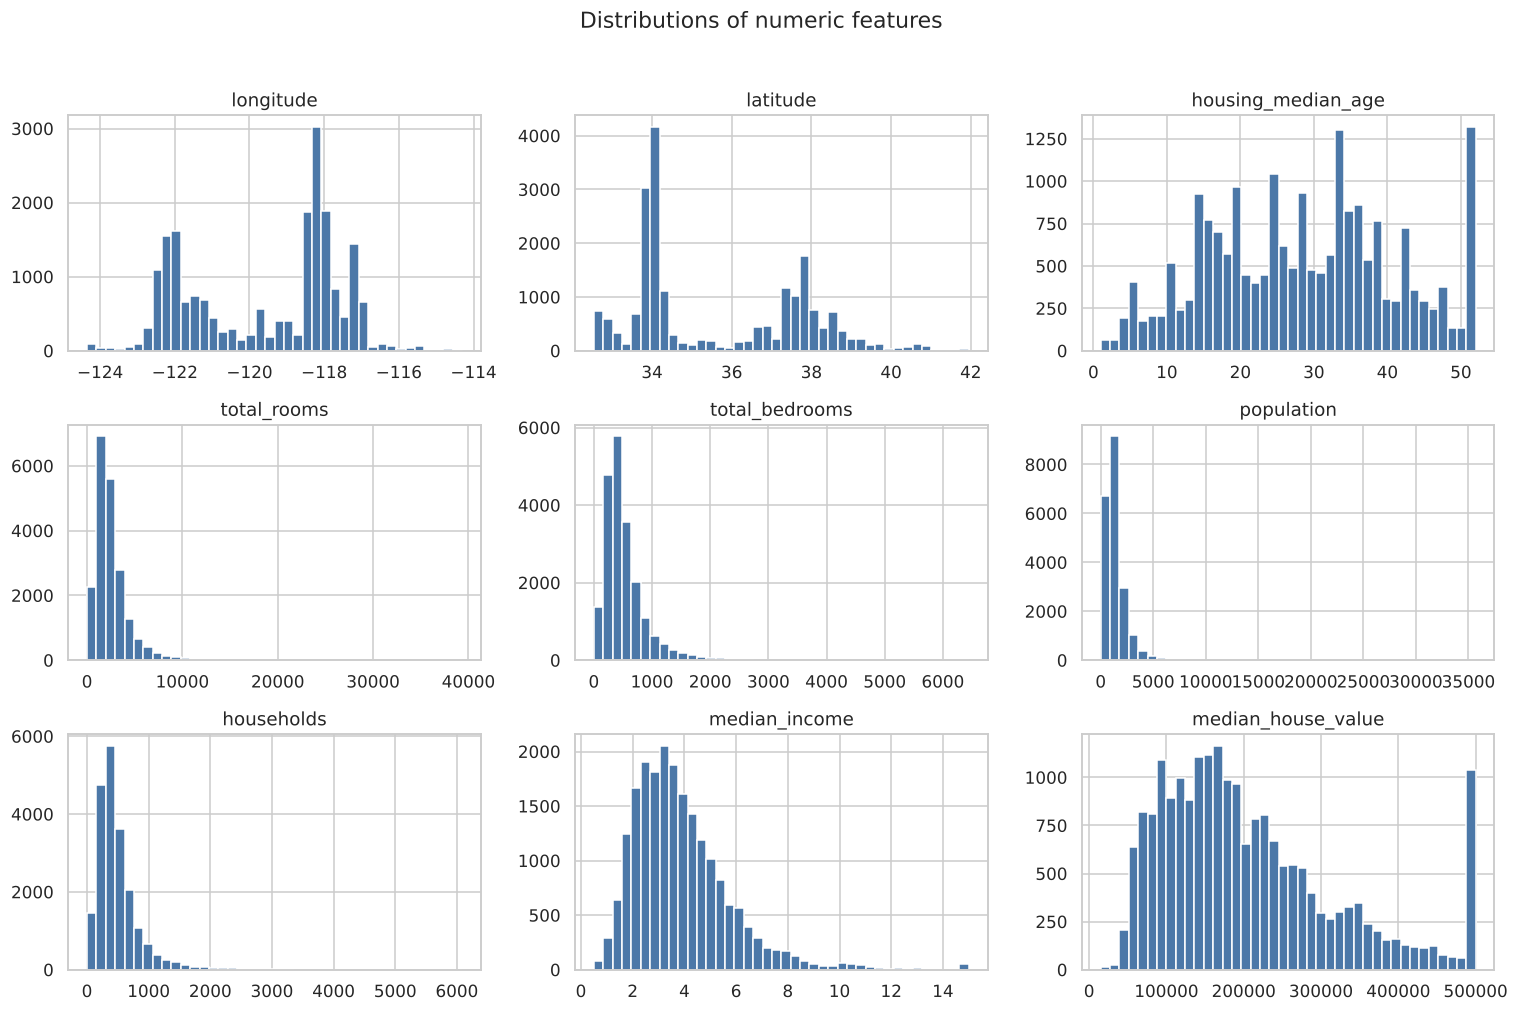

In [7]:
num_cols = eda.select_dtypes("number").columns.tolist()
eda[num_cols].hist(bins=40, figsize=(14, 9), color="#4C78A8", edgecolor="white")
plt.suptitle("Distributions of numeric features", y=1.02)
plt.tight_layout()
plt.show()

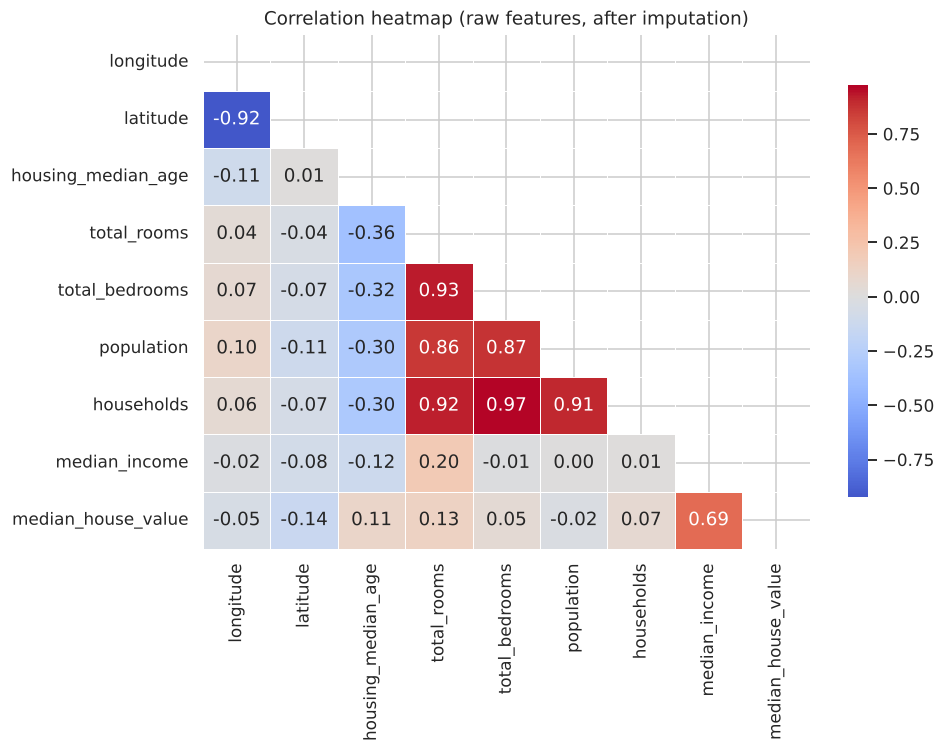

In [8]:
fig, ax = plt.subplots(figsize=(9, 7))
corr = eda[num_cols].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
ax.set_title("Correlation heatmap (raw features, after imputation)")
plt.tight_layout()
plt.show()

In [9]:
print("Correlation with median_house_value:")
corr["median_house_value"].drop("median_house_value").sort_values(ascending=False).round(3)

Correlation with median_house_value:


median_income         0.688
total_rooms           0.134
housing_median_age    0.106
households            0.066
total_bedrooms        0.049
population           -0.025
longitude            -0.046
latitude             -0.144
Name: median_house_value, dtype: float64

In [10]:
print(eda["ocean_proximity"].value_counts())
print("\nHouses at the price cap (500001):", (eda["median_house_value"] >= 500001).sum())

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

Houses at the price cap (500001): 965


**Observations**
- `median_income` is by far the strongest linear predictor of price.
- `total_rooms`, `total_bedrooms`, `population` and `households` are almost perfectly correlated with each other (they all measure district size). This is a classic multicollinearity source.
- `latitude` and `longitude` are strongly negatively correlated because California runs diagonally.
- `median_house_value` is censored at 500,001, which will cap how well any linear model can fit the top end.

## 4. Feature engineering (ratios and interactions)

In [11]:
def add_features(d):
    d = d.copy()
    # Per-household ratios (more meaningful than raw district totals)
    d["rooms_per_household"] = d["total_rooms"] / d["households"]
    d["bedrooms_per_room"] = d["total_bedrooms"] / d["total_rooms"]
    d["population_per_household"] = d["population"] / d["households"]
    # Interaction / non-linear terms
    # Variables are CENTERED (fixed reference constants near the dataset means)
    # before multiplying/squaring. Uncentered interactions are almost perfectly
    # collinear with their parent terms (VIF in the thousands).
    inc = d["median_income"] - 3.9
    age = d["housing_median_age"] - 28.6
    rph = d["rooms_per_household"] - 5.4
    lat = d["latitude"] - 35.6
    lon = d["longitude"] + 119.6
    d["income_x_age"] = inc * age
    d["income_x_rooms_per_hh"] = inc * rph
    d["income_sq"] = inc ** 2
    d["lat_x_lon"] = lat * lon
    return d

X_full = add_features(df.drop(columns="median_house_value"))
y = df["median_house_value"]
new_feats = ["rooms_per_household", "bedrooms_per_room", "population_per_household",
             "income_x_age", "income_x_rooms_per_hh", "income_sq", "lat_x_lon"]
X_full[new_feats].describe().T

,count,mean,std,min,25%,50%,75%,max
rooms_per_household,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
bedrooms_per_room,20433.0,0.213039,0.057983,0.100000,0.175427,0.203162,0.239821,1.000000
population_per_household,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
income_x_age,20640.0,-2.847160,25.283116,-295.262660,-11.682030,-0.936900,6.478995,259.742340
income_x_rooms_per_hh,20640.0,1.535643,5.092924,-276.430909,0.004559,0.575291,2.023909,186.728349
income_sq,20640.0,3.610008,9.446486,0.000000,0.316406,1.388744,3.540136,123.212220
lat_x_lon,20640.0,-3.955897,3.129901,-29.328000,-5.598150,-3.198600,-2.091000,2.485000


In [12]:
tmp = X_full[new_feats].copy()
tmp["median_house_value"] = y
tmp = tmp.fillna(tmp.median())
tmp.corr()["median_house_value"].drop("median_house_value").sort_values(ascending=False).round(3).to_frame("corr with target")

,corr with target
income_sq,0.372
income_x_rooms_per_hh,0.281
rooms_per_household,0.152
lat_x_lon,0.098
income_x_age,0.050
population_per_household,-0.024
bedrooms_per_room,-0.255


## 5. Multicollinearity: VIF diagnosis
The **Variance Inflation Factor** for feature *i* is `1 / (1 - R²ᵢ)`, where R²ᵢ comes from regressing feature *i* on all the others. A common rule of thumb: VIF > 10 signals serious collinearity.

In [13]:
def compute_vif(frame):
    from sklearn.linear_model import LinearRegression
    Z = (frame - frame.mean()) / frame.std()
    out = {}
    for c in Z.columns:
        others = Z.drop(columns=c)
        r2 = LinearRegression().fit(others, Z[c]).score(others, Z[c])
        out[c] = 1.0 / (1.0 - r2) if r2 < 1 else np.inf
    return pd.Series(out, name="VIF").sort_values(ascending=False)

num_all = X_full.select_dtypes("number")
num_all = num_all.fillna(num_all.median())   # diagnostic only
vif_before = compute_vif(num_all)
vif_before.round(1).to_frame()

,VIF
total_bedrooms,34.4
households,34.1
total_rooms,18.0
latitude,10.2
longitude,9.5
population,6.8
median_income,3.8
bedrooms_per_room,2.9
income_sq,2.6
income_x_rooms_per_hh,2.0


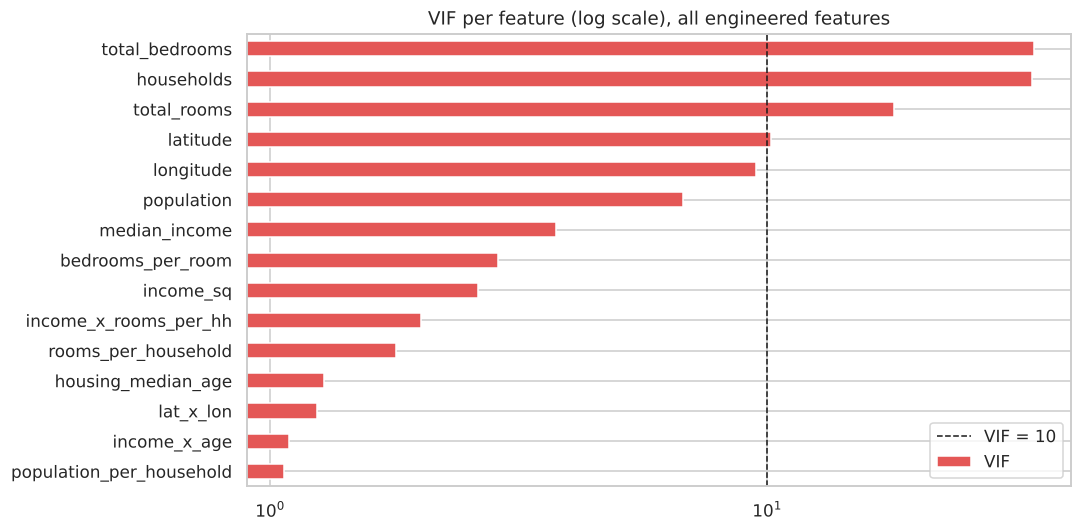

In [14]:
fig, ax = plt.subplots(figsize=(10, 5))
vif_before.sort_values().plot.barh(ax=ax, color="#E45756")
ax.axvline(10, color="k", ls="--", lw=1, label="VIF = 10")
ax.set_xscale("log")
ax.set_title("VIF per feature (log scale), all engineered features")
ax.legend()
plt.tight_layout()
plt.show()

**Handling strategy (two layers)**

1. *Structural*: the raw count columns `total_rooms`, `total_bedrooms` and `households` are now redundant, because the per-household ratios carry the same information without the size effect. We drop them.
2. *Statistical*: the remaining collinearity (e.g. `latitude` vs `longitude`, income vs its own square and interactions) carries real signal, so we keep it and let **Ridge / Lasso regularization** stabilize the coefficients rather than throwing the features away.

In [15]:
drop_cols = ["total_rooms", "total_bedrooms", "households"]
X_pruned = X_full.drop(columns=drop_cols)
num_pruned = X_pruned.select_dtypes("number")
vif_after = compute_vif(num_pruned.fillna(num_pruned.median()))

cmp = pd.concat([vif_before.rename("VIF before"), vif_after.rename("VIF after")], axis=1)
cmp.sort_values("VIF before", ascending=False).round(1)

,VIF before,VIF after
total_bedrooms,34.4,NaN
households,34.1,NaN
total_rooms,18.0,NaN
latitude,10.2,10.0
longitude,9.5,9.4
population,6.8,1.1
median_income,3.8,3.6
bedrooms_per_room,2.9,2.1
income_sq,2.6,2.6
income_x_rooms_per_hh,2.0,2.0


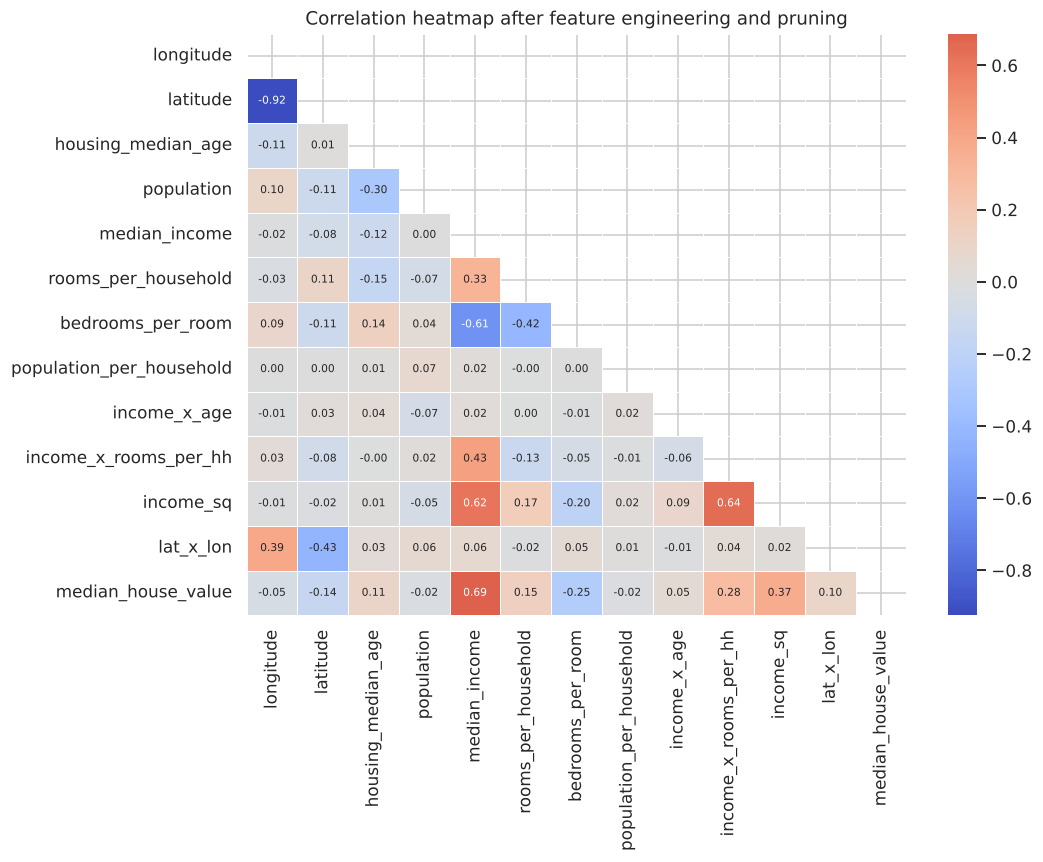

In [16]:
fig, ax = plt.subplots(figsize=(10, 8))
c2 = num_pruned.fillna(num_pruned.median()).assign(median_house_value=y).corr()
sns.heatmap(c2, mask=np.triu(np.ones_like(c2, dtype=bool)), annot=True, fmt=".2f",
            cmap="coolwarm", center=0, linewidths=.4, annot_kws={"size": 7}, ax=ax)
ax.set_title("Correlation heatmap after feature engineering and pruning")
plt.tight_layout()
plt.show()

## 6. Train/test split and preprocessing

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X_pruned, y, test_size=0.2, random_state=RANDOM_STATE)
print("Train:", X_train.shape, " Test:", X_test.shape)

cat_cols = ["ocean_proximity"]
num_cols_model = [c for c in X_pruned.columns if c not in cat_cols]

preprocess = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")),
                      ("scale", StandardScaler())]), num_cols_model),
    ("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cat_cols),
])
preprocess

Train: (16512, 13)  Test: (4128, 13)


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

## 7. Model fitting

### 7a. OLS baseline

In [18]:
ols = Pipeline([("prep", preprocess), ("model", LinearRegression())])
ols.fit(X_train, y_train)
print("OLS fitted.")

OLS fitted.


### 7b. Ridge (L2) with `GridSearchCV`
5-fold CV over a log-spaced alpha grid, scored by RMSE.

In [19]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

ridge_pipe = Pipeline([("prep", preprocess), ("model", Ridge(random_state=RANDOM_STATE))])
ridge_grid = GridSearchCV(
    ridge_pipe,
    param_grid={"model__alpha": np.logspace(-3, 3, 13)},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, return_train_score=True)
ridge_grid.fit(X_train, y_train)

print("Best Ridge alpha:", ridge_grid.best_params_["model__alpha"])
print("Best CV RMSE   :", round(-ridge_grid.best_score_, 2))

Best Ridge alpha: 1.0
Best CV RMSE   : 69440.26


### 7c. Lasso (L1) with `GridSearchCV`

In [20]:
lasso_pipe = Pipeline([("prep", preprocess),
                       ("model", Lasso(max_iter=50000, random_state=RANDOM_STATE))])
lasso_grid = GridSearchCV(
    lasso_pipe,
    param_grid={"model__alpha": np.logspace(-2, 3, 11)},
    scoring="neg_root_mean_squared_error", cv=cv, n_jobs=-1, return_train_score=True)
lasso_grid.fit(X_train, y_train)

print("Best Lasso alpha:", lasso_grid.best_params_["model__alpha"])
print("Best CV RMSE    :", round(-lasso_grid.best_score_, 2))

Best Lasso alpha: 10.0
Best CV RMSE    : 69445.6


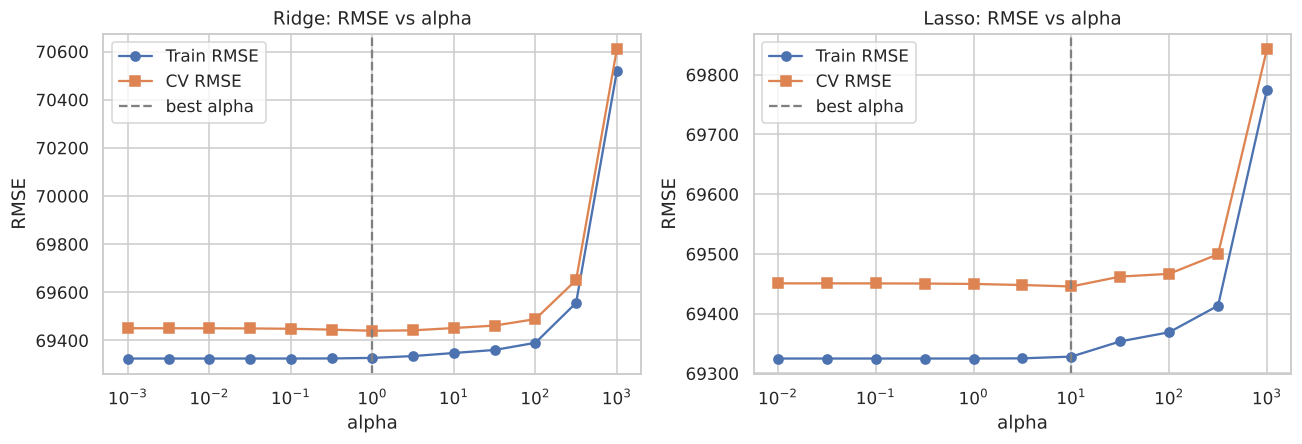

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharey=False)
for ax, grid, name in zip(axes, [ridge_grid, lasso_grid], ["Ridge", "Lasso"]):
    r = pd.DataFrame(grid.cv_results_)
    a = r["param_model__alpha"].astype(float)
    ax.plot(a, -r["mean_train_score"], "o-", label="Train RMSE")
    ax.plot(a, -r["mean_test_score"], "s-", label="CV RMSE")
    ax.axvline(grid.best_params_["model__alpha"], color="gray", ls="--", label="best alpha")
    ax.set_xscale("log")
    ax.set_xlabel("alpha"); ax.set_ylabel("RMSE")
    ax.set_title(f"{name}: RMSE vs alpha")
    ax.legend()
plt.tight_layout()
plt.show()

## 8. Model comparison (RMSE, MAE, R²)

In [22]:
models = {
    "OLS": ols,
    "Ridge (L2)": ridge_grid.best_estimator_,
    "Lasso (L1)": lasso_grid.best_estimator_,
}

def evaluate(model, X, y_true):
    p = model.predict(X)
    return {"RMSE": np.sqrt(mean_squared_error(y_true, p)),
            "MAE": mean_absolute_error(y_true, p),
            "R2": r2_score(y_true, p)}

rows = []
for name, m in models.items():
    tr, te = evaluate(m, X_train, y_train), evaluate(m, X_test, y_test)
    rows.append({"Model": name,
                 "Train RMSE": tr["RMSE"], "Test RMSE": te["RMSE"],
                 "Train MAE": tr["MAE"], "Test MAE": te["MAE"],
                 "Train R2": tr["R2"], "Test R2": te["R2"]})
results = pd.DataFrame(rows).set_index("Model")
results.round(4).style.format("{:,.4f}", subset=["Train R2", "Test R2"]) \
       .format("{:,.1f}", subset=[c for c in results.columns if "R2" not in c]) \
       .highlight_min(subset=["Test RMSE", "Test MAE"], color="#c7e9c0") \
       .highlight_max(subset=["Test R2"], color="#c7e9c0")

,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2
Model,,,,,,
OLS,"69,338.9","71,291.0","50,777.7","51,185.7",0.6403,0.6122
Ridge (L2),"69,340.4","71,300.4","50,779.0","51,193.4",0.6403,0.6120
Lasso (L1),"69,341.9","71,301.8","50,777.4","51,195.1",0.6403,0.6120


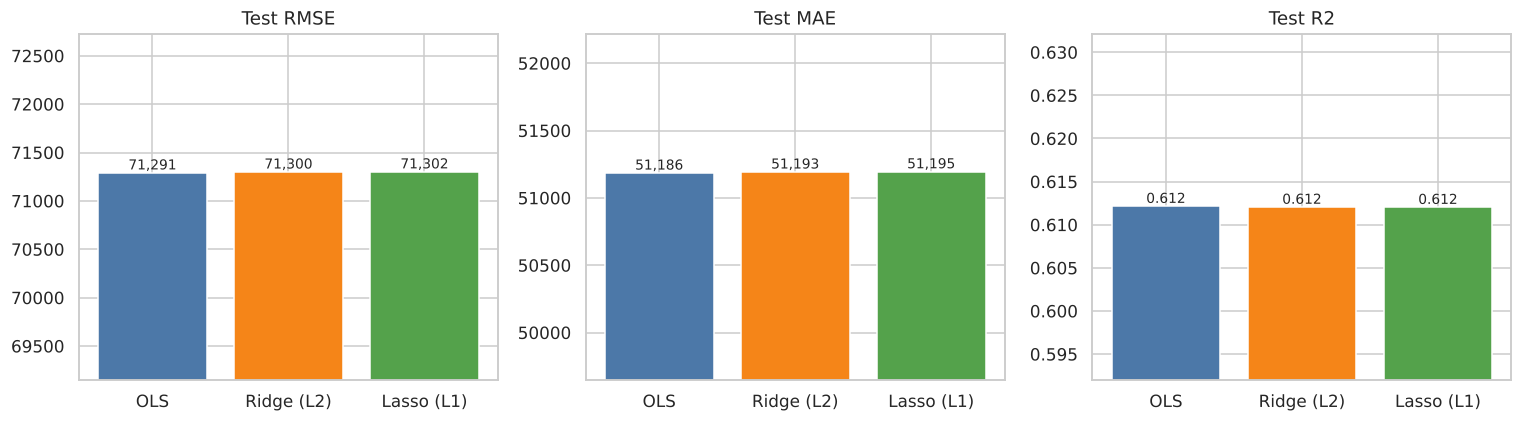

In [23]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, metric in zip(axes, ["RMSE", "MAE", "R2"]):
    vals = results[f"Test {metric}"]
    bars = ax.bar(vals.index, vals.values, color=["#4C78A8", "#F58518", "#54A24B"])
    ax.set_title(f"Test {metric}")
    for b, v in zip(bars, vals.values):
        ax.text(b.get_x() + b.get_width() / 2, v, f"{v:,.3f}" if metric == "R2" else f"{v:,.0f}",
                ha="center", va="bottom", fontsize=9)
    if metric == "R2":
        ax.set_ylim(vals.min() - 0.02, vals.max() + 0.02)
    else:
        ax.set_ylim(vals.min() * 0.97, vals.max() * 1.02)
plt.tight_layout()
plt.show()

## 9. Predicted vs actual

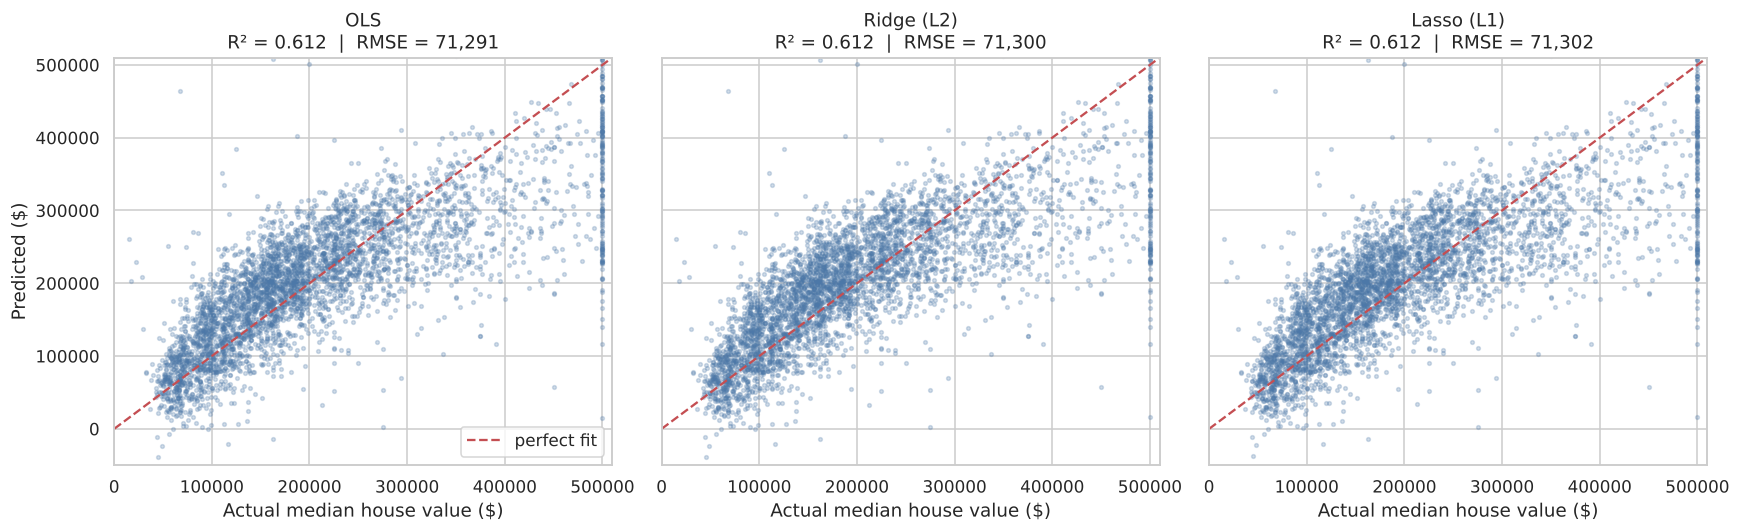

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True, sharey=True)
lim = [0, y_test.max() * 1.02]
for ax, (name, m) in zip(axes, models.items()):
    pred = m.predict(X_test)
    ax.scatter(y_test, pred, s=6, alpha=.25, color="#4C78A8")
    ax.plot(lim, lim, "r--", lw=1.5, label="perfect fit")
    ax.set_xlim(lim); ax.set_ylim(-50000, lim[1])
    ax.set_title(f"{name}\nR² = {r2_score(y_test, pred):.3f}  |  RMSE = {np.sqrt(mean_squared_error(y_test, pred)):,.0f}")
    ax.set_xlabel("Actual median house value ($)")
axes[0].set_ylabel("Predicted ($)")
axes[0].legend()
plt.tight_layout()
plt.show()

## 10. Residual distributions

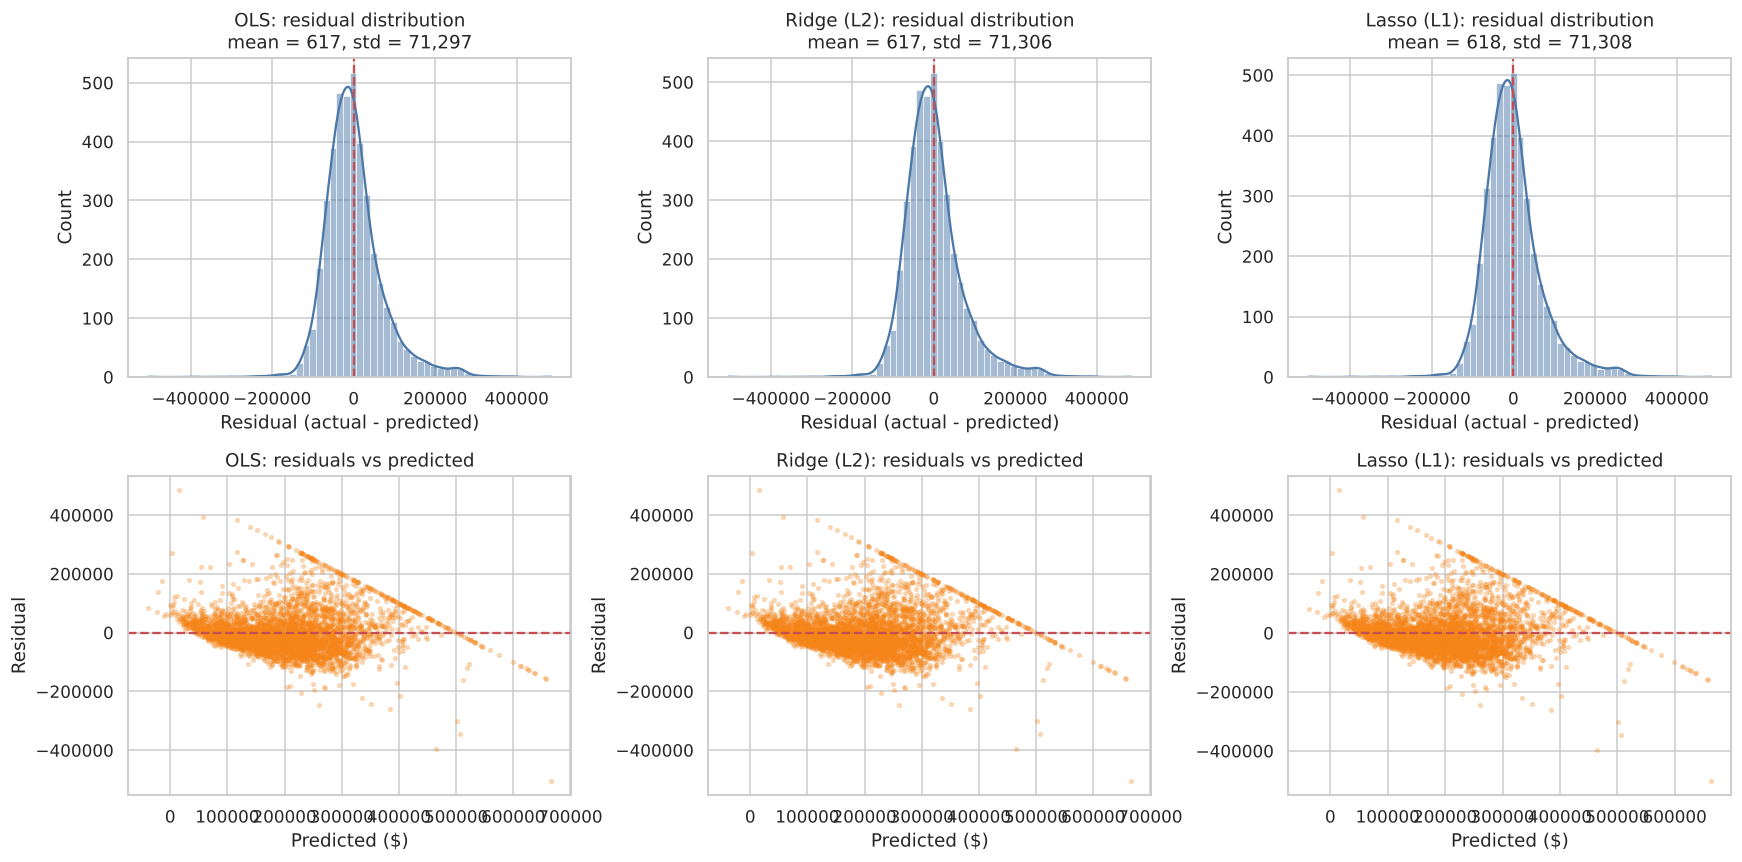

In [25]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for j, (name, m) in enumerate(models.items()):
    pred = m.predict(X_test)
    res = y_test - pred
    sns.histplot(res, kde=True, bins=60, color="#4C78A8", ax=axes[0, j])
    axes[0, j].axvline(0, color="r", ls="--")
    axes[0, j].set_title(f"{name}: residual distribution\nmean = {res.mean():,.0f}, std = {res.std():,.0f}")
    axes[0, j].set_xlabel("Residual (actual - predicted)")

    axes[1, j].scatter(pred, res, s=6, alpha=.25, color="#F58518")
    axes[1, j].axhline(0, color="r", ls="--")
    axes[1, j].set_title(f"{name}: residuals vs predicted")
    axes[1, j].set_xlabel("Predicted ($)"); axes[1, j].set_ylabel("Residual")
plt.tight_layout()
plt.show()

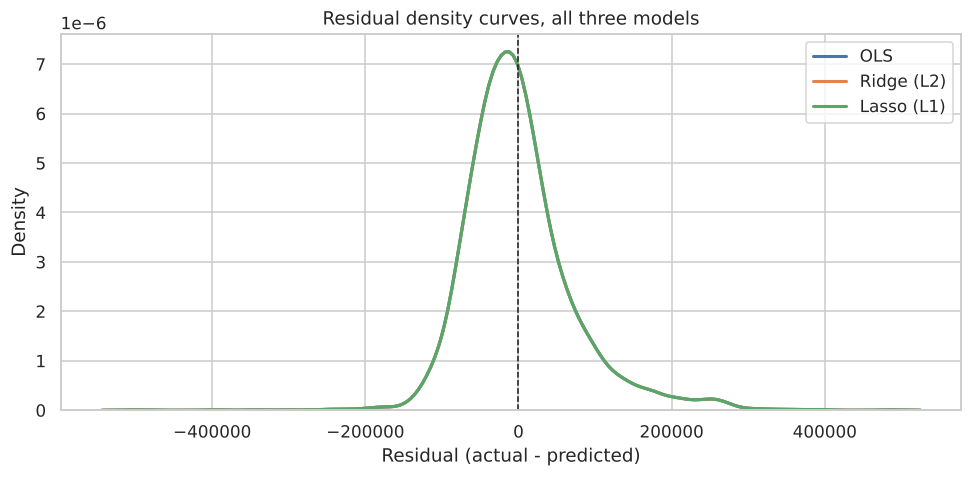

In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for name, m in models.items():
    sns.kdeplot(y_test - m.predict(X_test), label=name, ax=ax, lw=2)
ax.axvline(0, color="k", ls="--", lw=1)
ax.set_title("Residual density curves, all three models")
ax.set_xlabel("Residual (actual - predicted)")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Coefficients: what regularization did

In [27]:
feat_names = ols.named_steps["prep"].get_feature_names_out()
coef = pd.DataFrame({
    "OLS": ols.named_steps["model"].coef_,
    "Ridge": ridge_grid.best_estimator_.named_steps["model"].coef_,
    "Lasso": lasso_grid.best_estimator_.named_steps["model"].coef_,
}, index=[f.split("__")[1] for f in feat_names])

print("Lasso zeroed-out features:", list(coef.index[coef["Lasso"].abs() < 1e-8]) or "none")
coef.round(0).sort_values("OLS", key=abs, ascending=False)

Lasso zeroed-out features: none


,OLS,Ridge,Lasso
ocean_proximity_ISLAND,145086.0,116046.0,103811.0
median_income,94511.0,94490.0,94478.0
longitude,-43681.0,-43669.0,-43548.0
latitude,-39206.0,-39200.0,-39062.0
ocean_proximity_INLAND,-37885.0,-37902.0,-37996.0
bedrooms_per_room,24531.0,24526.0,24504.0
income_sq,-15732.0,-15722.0,-15674.0
ocean_proximity_NEAR OCEAN,14921.0,14900.0,14810.0
housing_median_age,12135.0,12138.0,12142.0
rooms_per_household,8351.0,8355.0,8316.0


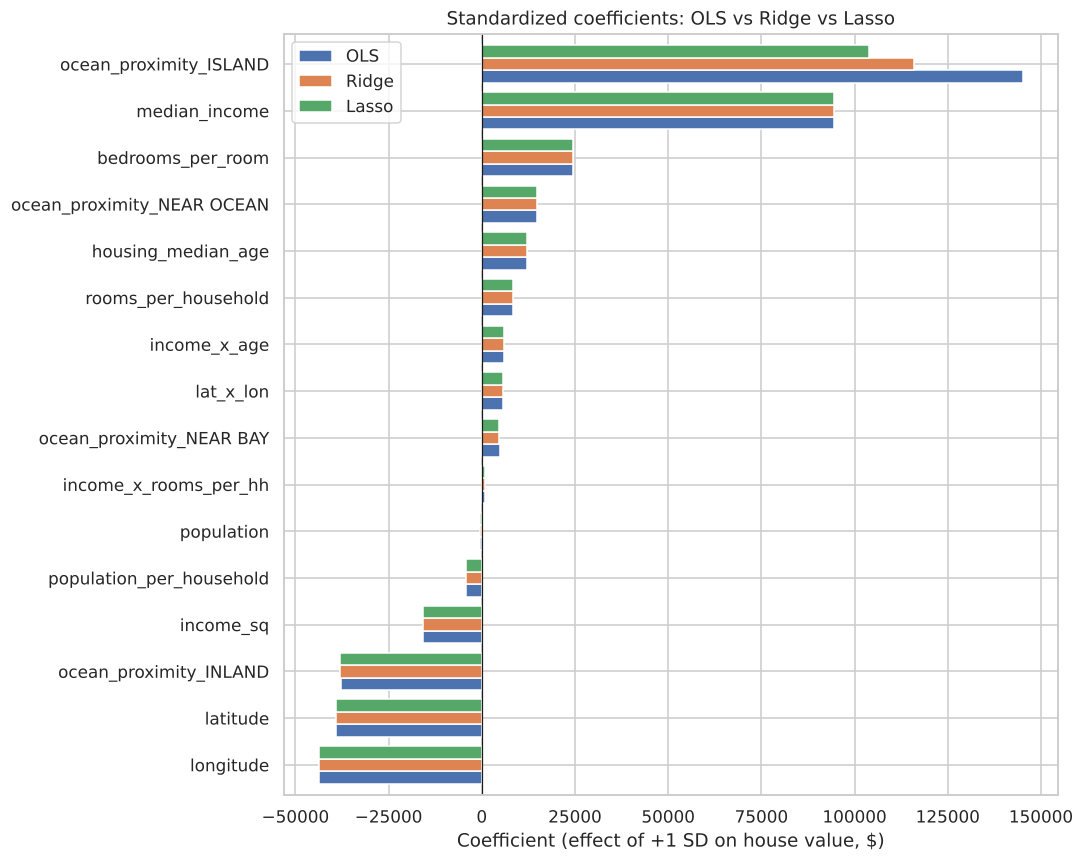

In [28]:
ax = coef.sort_values("OLS").plot.barh(figsize=(10, 8), width=.8)
ax.axvline(0, color="k", lw=.8)
ax.set_title("Standardized coefficients: OLS vs Ridge vs Lasso")
ax.set_xlabel("Coefficient (effect of +1 SD on house value, $)")
plt.tight_layout()
plt.show()

### Coefficient paths across alpha
Fitted on the preprocessed training data, this shows how each penalty shrinks coefficients as alpha grows. Lasso drives weak features exactly to zero; Ridge only shrinks them.

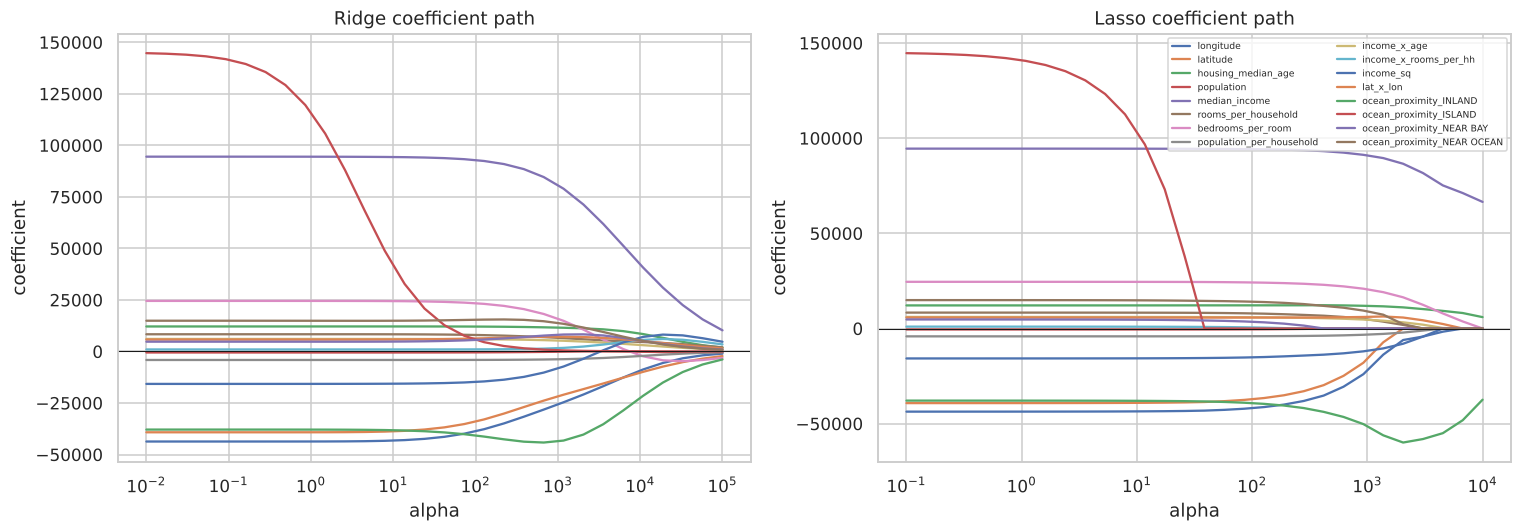

Features Lasso has zeroed at alpha = 10000: ['longitude', 'latitude', 'population', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household', 'income_x_age', 'income_x_rooms_per_hh', 'income_sq', 'lat_x_lon', 'ocean_proximity_ISLAND', 'ocean_proximity_NEAR BAY', 'ocean_proximity_NEAR OCEAN']


In [29]:
Xtr = preprocess.fit_transform(X_train)
names = [f.split("__")[1] for f in preprocess.get_feature_names_out()]
alphas_r = np.logspace(-2, 5, 30)
alphas_l = np.logspace(-1, 4, 30)
path_r = np.array([Ridge(alpha=a).fit(Xtr, y_train).coef_ for a in alphas_r])
path_l = np.array([Lasso(alpha=a, max_iter=50000).fit(Xtr, y_train).coef_ for a in alphas_l])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, path, al, name in zip(axes, [path_r, path_l], [alphas_r, alphas_l], ["Ridge", "Lasso"]):
    ax.plot(al, path)
    ax.set_xscale("log"); ax.axhline(0, color="k", lw=.7)
    ax.set_xlabel("alpha"); ax.set_ylabel("coefficient")
    ax.set_title(f"{name} coefficient path")
axes[1].legend(names, fontsize=6, ncol=2, loc="upper right")
plt.tight_layout()
plt.show()

last = pd.Series(path_l[-1], index=names)
print("Features Lasso has zeroed at alpha = %.0f:" % alphas_l[-1], list(last.index[last.abs() < 1e-8]))

## 12. Conclusions

In [30]:
best = results["Test RMSE"].idxmin()
print(f"Best model on test RMSE: {best}")
print(f"Ridge best alpha: {ridge_grid.best_params_['model__alpha']:.4g}")
print(f"Lasso best alpha: {lasso_grid.best_params_['model__alpha']:.4g}")
print(f"Lasso kept {(coef['Lasso'].abs() > 1e-8).sum()} of {len(coef)} features")
results.round(4)

Best model on test RMSE: OLS
Ridge best alpha: 1
Lasso best alpha: 10
Lasso kept 16 of 16 features


,Train RMSE,Test RMSE,Train MAE,Test MAE,Train R2,Test R2
Model,,,,,,
OLS,69338.8920,71291.0412,50777.6504,51185.6683,0.6403,0.6122
Ridge (L2),69340.3648,71300.3611,50779.0054,51193.4342,0.6403,0.6120
Lasso (L1),69341.9149,71301.8071,50777.3787,51195.1202,0.6403,0.6120


### Summary of findings

| Model | Test RMSE | Test MAE | Test R² | Best alpha |
|---|---|---|---|---|
| OLS | 71,291 | 51,186 | 0.6122 | n/a |
| Ridge (L2) | 71,300 | 51,193 | 0.6120 | 1.0 |
| Lasso (L1) | 71,302 | 51,195 | 0.6120 | 10.0 |

1. **All three models perform essentially the same** (test R² about 0.61, RMSE about $71k). The differences are under $15, far smaller than any meaningful gap. With about 16,500 training rows and only 16 features, OLS has very little variance to cut, so regularization has almost nothing to fix.
2. **Multicollinearity was handled mainly by feature design.** Dropping the redundant raw counts (`total_rooms`, `total_bedrooms`, `households`) and **centering** variables before building interactions took the worst VIFs from 13,000+ down to about 10 (only `latitude` / `longitude`, which are geographically coupled and worth keeping).
3. **Regularization still does its job where collinearity is real.** The `ocean_proximity_ISLAND` coefficient (only 5 samples) is shrunk from about 145k (OLS) to 116k (Ridge) and 104k (Lasso). The Lasso path plot shows weak features being zeroed as alpha grows, while at the CV-optimal alpha it keeps all 16 features.
4. **Residuals**: roughly centered at zero but with a heavy right tail and a visible diagonal band in predictions vs actual, caused by the censored target (house values capped at $500,001) and non-linear geography that a linear model cannot capture.
5. **Where to go next**: R² is limited by the linear form, not by overfitting. Tree-based models (e.g. gradient boosting) or distance-to-city features would likely help far more than tuning alpha.